# `fSumEnergyBundleReg / E_ν` versus `E_ν`

For events whose neutrino vertex lies inside a cluster: how the muon's share of the neutrino
energy depends on the neutrino energy.

| quantity | HDF5 path | ROOT branch |
|---|---|---|
| `E_ν` | `prime_prty[:, 2]` | `BMCEvent.fPrimaryParticleEnergy` |
| `Reg` | `muons_prty/aggregate[:, 1]` | `BMCEvent.fSumEnergyBundleReg` |
| vertex inside the cluster | `e_at_entry_status[:, 0] ∈ (1, 5)` | derived (see `doc/hdf5_energy_truth.md`) |
| ν / ν̄ | `prime_prty[:, 3]` = ±1 | `BMCEvent.fNucleonN` |

`Reg` is the muon's energy at the registration area; the vertex lies inside it, so for these
events `Reg` is the muon's energy at birth. Both files are read, nothing is written.

`prime_prty[:, 3]` is `+1` for neutrinos and `−1` for antineutrinos in the neutrino
productions (see `doc/claims_log.md`; status `consistent`, not verified against NUGEN source).
`nue2_2020` contains only `+1`, so the split is shown for `nuatm_2020` only.


In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA = Path("/home/albert/Baikal2025/data_manager/data/h5datasets")
main = h5py.File(DATA / "baikal_mc_merged.h5", "r")
twin = h5py.File(DATA / "baikal_mc_merged_energy_truth.h5", "r")

PRODUCTIONS = ["nuatm_2020", "nue2_2020"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f2f7fd", "#86b6ef", "#2a78d6", "#104281"])

In [2]:
def load(production, every=1):
    e_nu, reg, inside, sign = [], [], [], []
    for part in sorted(main[f"{production}/ev_ids"].keys())[::every]:
        prime = main[f"{production}/prime_prty/{part}/data"]
        e_nu.append(prime[:, 2])
        sign.append(np.sign(prime[:, 3]).astype(np.int8))
        reg.append(main[f"{production}/muons_prty/aggregate/{part}/data"][:, 1])
        # status 1 = born inside, status 5 = sentinel born inside; both belong here
        inside.append(np.isin(twin[f"{production}/e_at_entry_status/{part}/data"][:, 0], (1, 5)))
    return (np.concatenate(e_nu).astype(np.float64),
            np.concatenate(reg).astype(np.float64),
            np.concatenate(inside),
            np.concatenate(sign))

data = {p: load(p) for p in PRODUCTIONS}
for p, (e, r, i, s) in data.items():
    print(f"{p:12s} events {len(e):>9,}   vertex inside a cluster: {i.sum():>8,}"
          f"   ν: {(i & (s > 0)).sum():>8,}   ν̄: {(i & (s < 0)).sum():>8,}")


nuatm_2020   events 66,695,937   vertex inside a cluster: 16,059,373   ν: 11,266,717   ν̄: 4,792,656
nue2_2020    events 7,665,396   vertex inside a cluster:  990,994   ν:  990,994   ν̄:        0


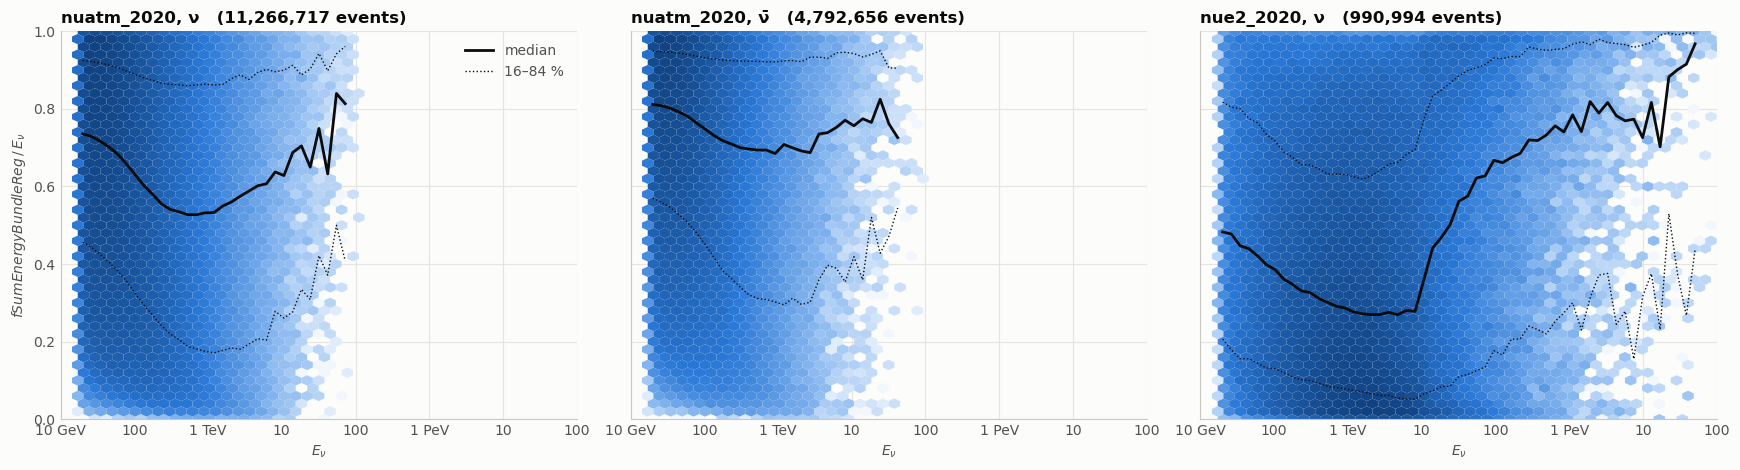

In [3]:
PANELS = [("nuatm_2020", +1, "ν"), ("nuatm_2020", -1, "ν̄"), ("nue2_2020", +1, "ν")]

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8), sharey=True)
fig.patch.set_facecolor(SURFACE)

edges = np.logspace(1, 8, 60)

for ax, (production, species, label) in zip(axes, PANELS):
    e_nu, reg, inside, sign = data[production]
    sel = inside & (sign == species)
    e_nu, ratio = e_nu[sel], (reg / e_nu)[sel]

    ax.set_facecolor(SURFACE)
    ax.hexbin(np.log10(e_nu), ratio, gridsize=45, extent=(1, 8, 0, 1), cmap=SEQ,
              bins="log", mincnt=1, linewidths=0)

    centres = 0.5 * (edges[:-1] + edges[1:])
    q = np.full((3, len(centres)), np.nan)
    for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        s = (e_nu >= lo) & (e_nu < hi)
        if s.sum() > 50:
            q[:, k] = np.percentile(ratio[s], [16, 50, 84])
    ax.plot(np.log10(centres), q[1], color=INK, linewidth=2, label="median")
    ax.plot(np.log10(centres), q[0], color=INK, linewidth=1, linestyle=":", label="16–84 %")
    ax.plot(np.log10(centres), q[2], color=INK, linewidth=1, linestyle=":")

    ax.set_xlim(1, 8); ax.set_ylim(0, 1)
    ax.set_xticks([1, 2, 3, 4, 5, 6, 7, 8])
    ax.set_xticklabels(["10 GeV", "100", "1 TeV", "10", "100", "1 PeV", "10", "100"])
    ax.set_xlabel("$E_\\nu$", color=MUTED)
    ax.set_title(f"{production}, {label}   ({sel.sum():,} events)", loc="left",
                 fontsize=12, fontweight="bold", color=INK)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c9c8c3")
    ax.tick_params(colors=MUTED, length=0)

axes[0].set_ylabel("$fSumEnergyBundleReg\\,/\\,E_\\nu$", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED, loc="upper right")
plt.tight_layout()
plt.show()


In [4]:
PRODUCTIONS

['nuatm_2020', 'nue2_2020']

## Reading the plot

`Reg/E_ν` is the muon's share of the neutrino energy, so a pure charged-current picture puts it
at `1 − y`, with `y` the inelasticity: about 0.5 at 100 GeV, falling to 0.25–0.30 at TeV–PeV
(measured by IceCube over 1–100 TeV).

`nuatm_2020` is split into neutrinos and antineutrinos (`prime_prty[:, 3]`); `nue2_2020`
contains only neutrinos. The density fills nearly the whole square in every panel: the split
varies from event to event over almost the full range. What differs is the median line.

The median line is the quantity of interest. A median that rises towards 1 is the signature of
`1 − y` in the muon slot; a median that falls is not. The antineutrino median sits below the
neutrino one at low energy, and the neutrino-only `nuatm` curve is still far from `nue2` there.


## Why the vertical axis is `y`

`fSumEnergyBundleReg` is the muon's energy in the registration area. For the events plotted
here the vertex lies inside that area, so the muon has not travelled yet and `Reg` is its
energy at birth. The hadronic system then carries the rest, `y = 1 − Reg/E_ν`.

Two properties of these files belong with the plot:

- `fSumEnergyBundleReg` **plus the cascade recorded at the vertex equals `fPrimaryParticleEnergy`
  exactly** — within 0.1 % for 99.6–100 % of events, in every energy bin. The two are
  complements computed by the generator, so the split carries one number per event, not two
  independent measurements.
- In `nue2_2020` the split has a **step at exactly 10 TeV**: `y` drops from 0.73 to 0.50 across
  that boundary, with flat plateaus on both sides. `nuatm_2020` shows no step there, for
  neutrinos or antineutrinos. A step at a round energy is a boundary in the generator, not a
  physical effect.


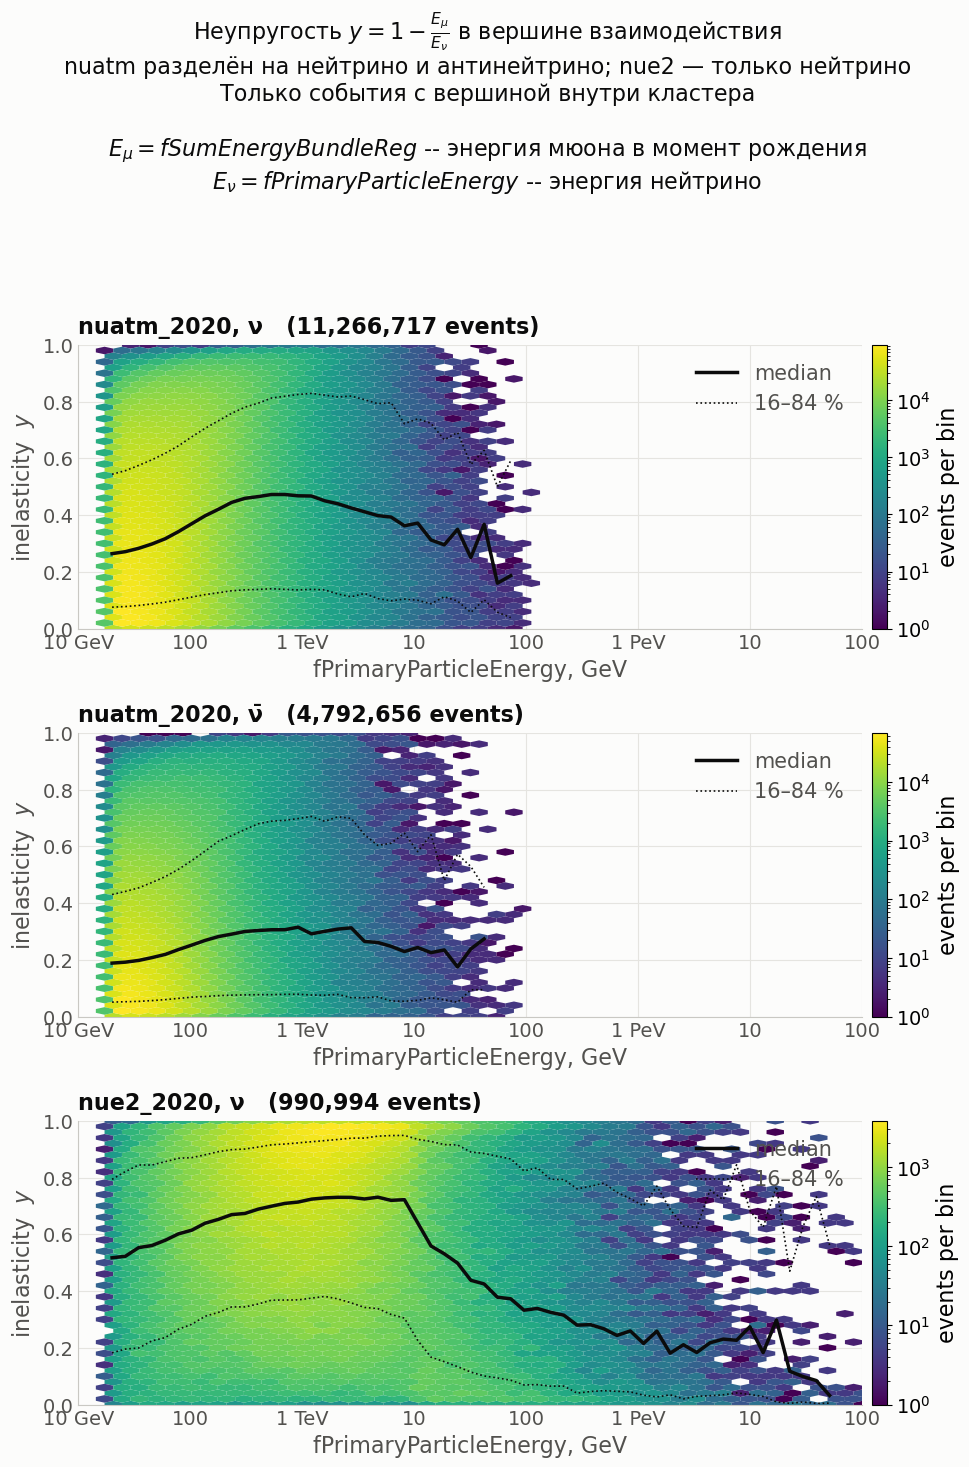

In [5]:
plt.rcParams.update({"font.size": 15, "axes.labelsize": 16, "axes.titlesize": 16,
                     "xtick.labelsize": 14, "ytick.labelsize": 14})
edges = np.logspace(1, 8, 60)
PANELS = [("nuatm_2020", +1, "ν"), ("nuatm_2020", -1, "ν̄"), ("nue2_2020", +1, "ν")]

fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=False, sharey=True)
fig.patch.set_facecolor(SURFACE)

for ax, (production, species, label) in zip(axes, PANELS):
    e_nu, reg, inside, sign = data[production]
    sel = inside & (sign == species)
    e_nu, y = e_nu[sel], (1 - reg / e_nu)[sel]

    ax.set_facecolor(SURFACE)
    hb = ax.hexbin(np.log10(e_nu), y, gridsize=45, extent=(1, 8, 0, 1), cmap="viridis",
                   bins="log", mincnt=1, linewidths=0)
    fig.colorbar(hb, ax=ax, pad=0.012, fraction=0.046, label="events per bin")

    centres = 0.5 * (edges[:-1] + edges[1:])
    q = np.full((3, len(centres)), np.nan)
    for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        s = (e_nu >= lo) & (e_nu < hi)
        if s.sum() > 50:
            q[:, k] = np.percentile(y[s], [16, 50, 84])
    ax.plot(np.log10(centres), q[1], color=INK, linewidth=2.5, label="median")
    ax.plot(np.log10(centres), q[0], color=INK, linewidth=1.2, linestyle=":", label="16–84 %")
    ax.plot(np.log10(centres), q[2], color=INK, linewidth=1.2, linestyle=":")

    ax.set_xlim(1, 8); ax.set_ylim(0, 1)
    ax.set_ylabel("inelasticity  $y$", color=MUTED)
    ax.set_title(f"{production}, {label}   ({sel.sum():,} events)", loc="left",
                 fontweight="bold", color=INK, pad=8)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c9c8c3")
    ax.tick_params(colors=MUTED, length=0)
    ax.legend(frameon=False, labelcolor=MUTED, loc="upper right")

for ax in axes:
    ax.set_xticks(range(1, 9))
    ax.set_xticklabels(["10 GeV", "100", "1 TeV", "10", "100", "1 PeV", "10", "100"])
    ax.set_xlabel("fPrimaryParticleEnergy, GeV", color=MUTED)
fig.suptitle(
    r"Неупругость $y = 1 − \frac{E_{\mu}}{E_{\nu}}$" + " в вершине взаимодействия\n"
    "nuatm разделён на нейтрино и антинейтрино; nue2 — только нейтрино\n"
    "Только события с вершиной внутри кластера\n\n" +
    r"$E_\mu = fSumEnergyBundleReg$" + " -- энергия мюона в момент рождения\n" +
    r"$E_\nu = fPrimaryParticleEnergy$" + " -- энергия нейтрино",
             fontsize=16, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()
